First five rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

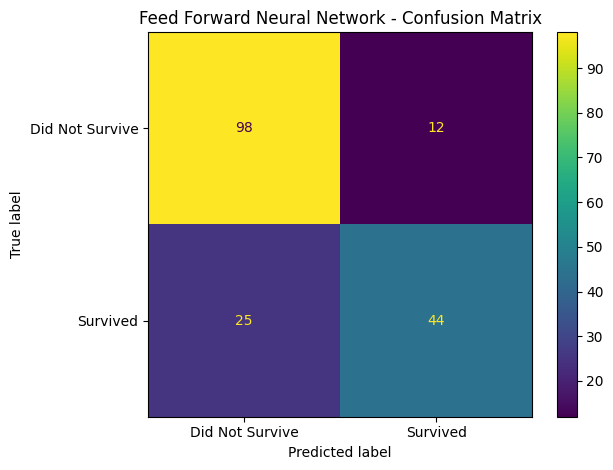

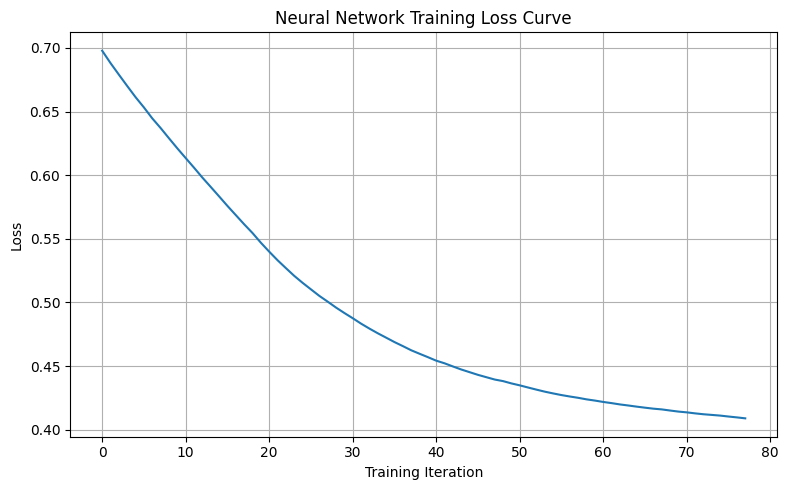


========== RESULT ==========
Feed Forward Neural Network classification completed.
The model predicted passenger survival.
Test accuracy: 79.33 %


In [6]:

# MACHINE LEARNING LAB - CO2
# PROGRAM 10: FEED FORWARD NEURAL NETWORK CLASSIFICATION
# Dataset: Titanic-Dataset.csv
# Platform: Google Colab

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. LOAD DATASET
# --------------------------------------------------

file_path = "/content/Titanic-Dataset.csv"

if not os.path.exists(file_path):
    csv_files = glob.glob("/content/*.csv")

    if len(csv_files) == 1:
        file_path = csv_files[0]
    else:
        raise FileNotFoundError(
            "Upload Titanic-Dataset.csv to Colab Files and try again."
        )

df = pd.read_csv(file_path)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


# --------------------------------------------------
# 2. SELECT FEATURES AND TARGET
# --------------------------------------------------

# Target: Survived (0 = Did not survive, 1 = Survived)
target = "Survived"

if target not in df.columns:
    raise ValueError("The dataset must contain a 'Survived' column.")

# Select useful passenger features.
feature_columns = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

# Keep only features that exist in the dataset.
feature_columns = [
    col for col in feature_columns if col in df.columns
]

X = df[feature_columns].copy()
y = df[target].copy()

# Remove rows where the target is missing.
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("\nSelected features:")
print(feature_columns)

print("\nTarget distribution:")
print(y.value_counts())


# --------------------------------------------------
# 3. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# --------------------------------------------------

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)


# --------------------------------------------------
# 4. SPLIT DATA INTO TRAINING AND TESTING SETS
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# --------------------------------------------------
# 5. PREPROCESS THE DATA
# --------------------------------------------------

# Numerical features: fill missing values and standardize.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features: fill missing values and encode text.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


# --------------------------------------------------
# 6. BUILD THE FEED FORWARD NEURAL NETWORK
# --------------------------------------------------

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("neural_network", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20
    ))
])


# --------------------------------------------------
# 7. TRAIN THE MODEL
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nFeed Forward Neural Network trained successfully!")


# --------------------------------------------------
# 8. MAKE PREDICTIONS
# --------------------------------------------------

y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Actual Survival": y_test.values,
    "Predicted Survival": y_pred
})

print("\nActual vs Predicted (first 10 rows):")
print(results.head(10))


# --------------------------------------------------
# 9. EVALUATE THE MODEL
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n========== MODEL EVALUATION ==========")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did Not Survive", "Survived"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


# --------------------------------------------------
# 10. VISUALIZE CONFUSION MATRIX
# --------------------------------------------------

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot()
plt.title("Feed Forward Neural Network - Confusion Matrix")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 11. PLOT TRAINING LOSS CURVE
# --------------------------------------------------

neural_network = model.named_steps["neural_network"]

plt.figure(figsize=(8, 5))
plt.plot(neural_network.loss_curve_)
plt.xlabel("Training Iteration")
plt.ylabel("Loss")
plt.title("Neural Network Training Loss Curve")
plt.grid(True)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 12. RESULT
# --------------------------------------------------

print("\n========== RESULT ==========")
print("Feed Forward Neural Network classification completed.")
print("The model predicted passenger survival.")
print("Test accuracy:", round(accuracy * 100, 2), "%")


First five rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

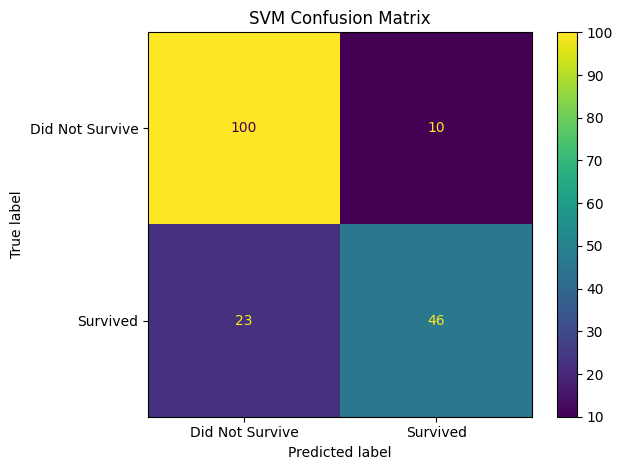

linear kernel accuracy: 77.65 %
poly kernel accuracy: 82.12 %
rbf kernel accuracy: 81.56 %
sigmoid kernel accuracy: 67.04 %


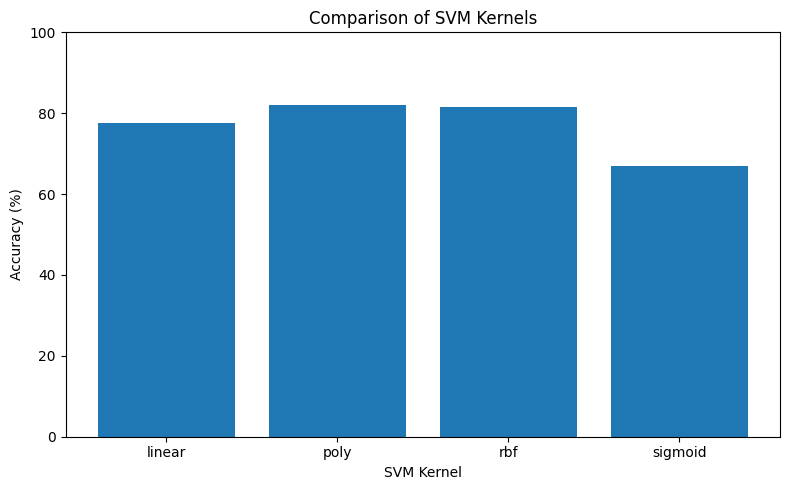


========== RESULT ==========
Support Vector Machine classification completed.
Best kernel on this test split: poly
Main SVM model accuracy: 81.56 %


In [7]:

# MACHINE LEARNING LAB - CO2
# PROGRAM 11: SUPPORT VECTOR MACHINE (SVM) CLASSIFICATION
# Dataset: Titanic-Dataset.csv
# Platform: Google Colab

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. LOAD DATASET
# --------------------------------------------------

file_path = "/content/Titanic-Dataset.csv"

if not os.path.exists(file_path):
    csv_files = glob.glob("/content/*.csv")

    if len(csv_files) == 1:
        file_path = csv_files[0]
    else:
        raise FileNotFoundError(
            "Upload Titanic-Dataset.csv to Colab Files and try again."
        )

df = pd.read_csv(file_path)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())


# --------------------------------------------------
# 2. SELECT FEATURES AND TARGET
# --------------------------------------------------

target = "Survived"

if target not in df.columns:
    raise ValueError("Dataset must contain a 'Survived' column.")

feature_columns = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

feature_columns = [
    col for col in feature_columns if col in df.columns
]

X = df[feature_columns].copy()
y = df[target].copy()

valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("\nSelected features:", feature_columns)

print("\nTarget distribution:")
print(y.value_counts())


# --------------------------------------------------
# 3. IDENTIFY FEATURE TYPES
# --------------------------------------------------

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()


# --------------------------------------------------
# 4. SPLIT THE DATA
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# --------------------------------------------------
# 5. PREPROCESS THE DATA
# --------------------------------------------------

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


# --------------------------------------------------
# 6. BUILD THE SVM CLASSIFIER
# --------------------------------------------------

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])


# --------------------------------------------------
# 7. TRAIN THE MODEL
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nSVM model trained successfully!")


# --------------------------------------------------
# 8. MAKE PREDICTIONS
# --------------------------------------------------

y_pred = model.predict(X_test)

print("\nFirst 10 predictions:")
print(y_pred[:10])


# --------------------------------------------------
# 9. EVALUATE THE MODEL
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n========== SVM MODEL EVALUATION ==========")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did Not Survive", "Survived"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


# --------------------------------------------------
# 10. PLOT CONFUSION MATRIX
# --------------------------------------------------

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot()
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 11. COMPARE SVM KERNELS
# --------------------------------------------------

kernels = ["linear", "poly", "rbf", "sigmoid"]
kernel_accuracies = []

for kernel_name in kernels:
    kernel_model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", SVC(
            kernel=kernel_name,
            C=1.0,
            gamma="scale"
        ))
    ])

    kernel_model.fit(X_train, y_train)
    kernel_pred = kernel_model.predict(X_test)

    score = accuracy_score(y_test, kernel_pred)
    kernel_accuracies.append(score)

    print(
        f"{kernel_name} kernel accuracy:",
        round(score * 100, 2), "%"
    )


# --------------------------------------------------
# 12. PLOT KERNEL COMPARISON
# --------------------------------------------------

plt.figure(figsize=(8, 5))
plt.bar(kernels, [score * 100 for score in kernel_accuracies])
plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of SVM Kernels")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 13. RESULT
# --------------------------------------------------

print("\n========== RESULT ==========")
print("Support Vector Machine classification completed.")
print("Best kernel on this test split:",
      kernels[int(np.argmax(kernel_accuracies))])
print("Main SVM model accuracy:", round(accuracy * 100, 2), "%")


First five rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

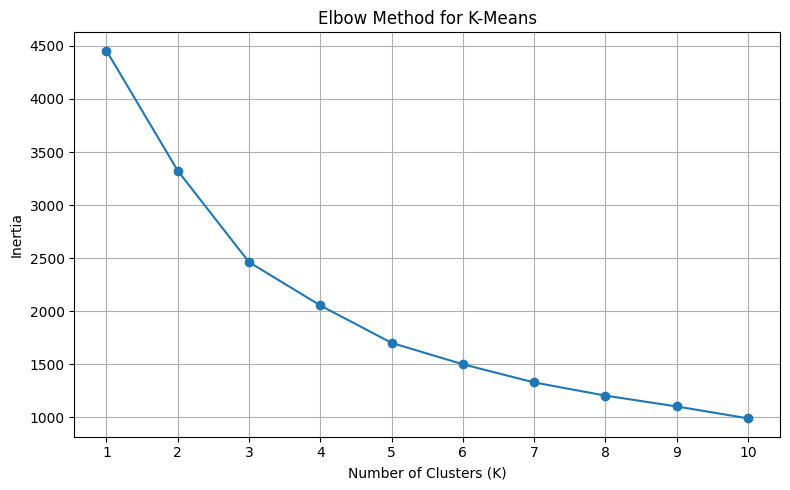


First 10 cluster assignments:
   Pclass   Age  SibSp  Parch     Fare  Cluster
0       3  22.0      1      0   7.2500        1
1       1  38.0      1      0  71.2833        2
2       3  26.0      0      0   7.9250        1
3       1  35.0      1      0  53.1000        2
4       3  35.0      0      0   8.0500        1
5       3   NaN      0      0   8.4583        1
6       1  54.0      0      0  51.8625        2
7       3   2.0      3      1  21.0750        0
8       3  27.0      0      2  11.1333        1
9       2  14.0      1      0  30.0708        1

Number of records in each cluster:
Cluster
0    110
1    542
2    239
Name: count, dtype: int64

Silhouette Score: 0.417
Silhouette score ranges from -1 to 1.
Higher values generally indicate better-separated clusters.


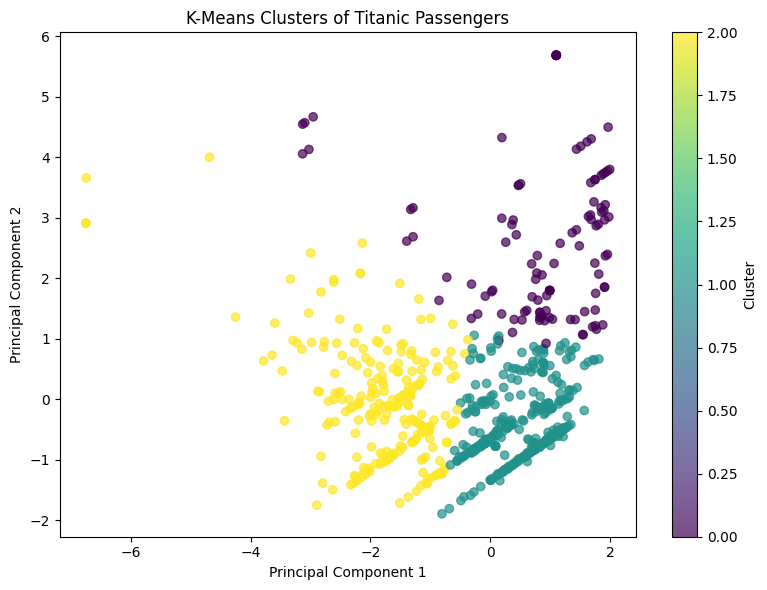


Average feature values by cluster:
         Pclass    Age  SibSp  Parch   Fare
Cluster                                    
0          2.57  13.36   2.34   1.94  45.92
1          2.77  27.72   0.23   0.11  12.19
2          1.14  41.15   0.36   0.28  71.27

========== RESULT ==========
K-Means clustering completed successfully.
The passenger records were grouped into 3 clusters.


In [8]:

# MACHINE LEARNING LAB - CO2
# PROGRAM 12: K-MEANS CLUSTERING
# Dataset: Titanic-Dataset.csv
# Platform: Google Colab

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# --------------------------------------------------
# 1. LOAD DATASET
# --------------------------------------------------

file_path = "/content/Titanic-Dataset.csv"

if not os.path.exists(file_path):
    csv_files = glob.glob("/content/*.csv")

    if len(csv_files) == 1:
        file_path = csv_files[0]
    else:
        raise FileNotFoundError(
            "Upload Titanic-Dataset.csv to Colab Files and try again."
        )

df = pd.read_csv(file_path)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)


# --------------------------------------------------
# 2. SELECT FEATURES
# --------------------------------------------------

# Use numerical passenger attributes.
# Survived is excluded because clustering is unsupervised.
feature_columns = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

feature_columns = [
    col for col in feature_columns if col in df.columns
]

if len(feature_columns) < 2:
    raise ValueError("At least two numerical features are required.")

X = df[feature_columns].copy()

print("\nFeatures used:")
print(feature_columns)

print("\nMissing values:")
print(X.isnull().sum())


# --------------------------------------------------
# 3. HANDLE MISSING VALUES
# --------------------------------------------------

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)


# --------------------------------------------------
# 4. STANDARDIZE THE FEATURES
# --------------------------------------------------

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nFeatures standardized successfully.")


# --------------------------------------------------
# 5. FIND A SUITABLE NUMBER OF CLUSTERS
#    USING THE ELBOW METHOD
# --------------------------------------------------

inertias = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. APPLY K-MEANS WITH K = 3
# --------------------------------------------------

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print("\nFirst 10 cluster assignments:")
print(df[feature_columns + ["Cluster"]].head(10))

print("\nNumber of records in each cluster:")
print(df["Cluster"].value_counts().sort_index())


# --------------------------------------------------
# 7. EVALUATE CLUSTERING
# --------------------------------------------------

score = silhouette_score(X_scaled, clusters)

print("\nSilhouette Score:", round(score, 4))
print("Silhouette score ranges from -1 to 1.")
print("Higher values generally indicate better-separated clusters.")


# --------------------------------------------------
# 8. VISUALIZE CLUSTERS USING PCA
# --------------------------------------------------

# PCA reduces the selected features to two dimensions for plotting.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters of Titanic Passengers")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 9. EXAMINE CLUSTER CHARACTERISTICS
# --------------------------------------------------

print("\nAverage feature values by cluster:")
print(df.groupby("Cluster")[feature_columns].mean().round(2))


# --------------------------------------------------
# 10. RESULT
# --------------------------------------------------

print("\n========== RESULT ==========")
print("K-Means clustering completed successfully.")
print("The passenger records were grouped into 3 clusters.")


First five rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   

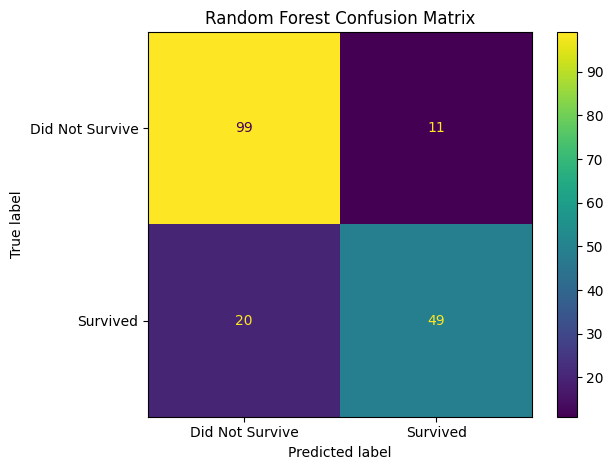


Feature Importance:
        Feature  Importance
      num__Fare    0.262894
       num__Age    0.255058
cat__Sex_female    0.157775
  cat__Sex_male    0.127494
    num__Pclass    0.078825
     num__SibSp    0.046493
     num__Parch    0.035771
cat__Embarked_S    0.016303
cat__Embarked_C    0.013343
cat__Embarked_Q    0.006045


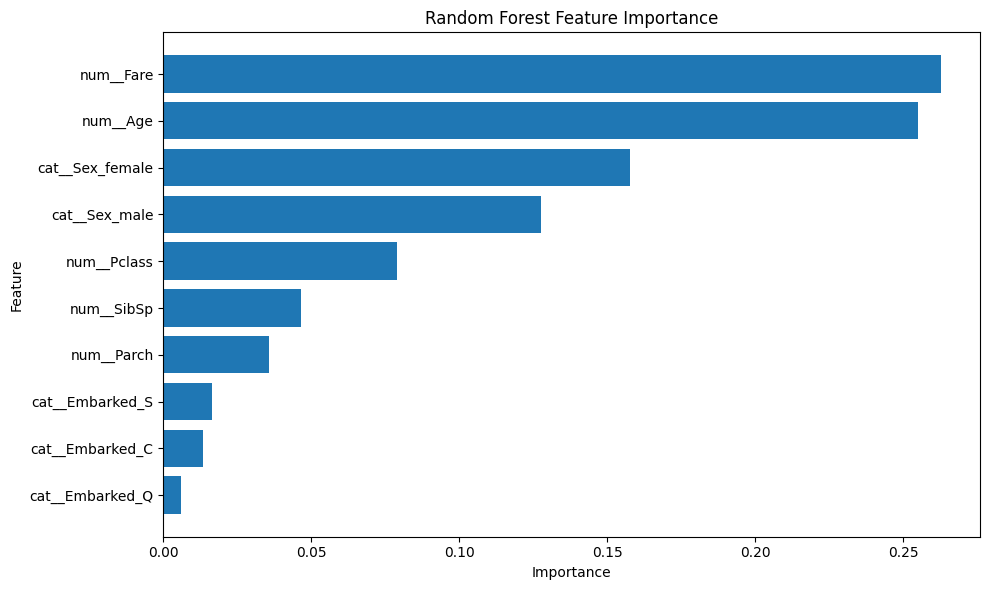


========== RESULT ==========
Random Forest classification completed.
The model predicted passenger survival.
Test accuracy: 82.68 %


In [9]:

# MACHINE LEARNING LAB - CO2
# PROGRAM 13: RANDOM FOREST CLASSIFICATION
# Dataset: Titanic-Dataset.csv
# Platform: Google Colab

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# --------------------------------------------------
# 1. LOAD DATASET
# --------------------------------------------------

file_path = "/content/Titanic-Dataset.csv"

if not os.path.exists(file_path):
    csv_files = glob.glob("/content/*.csv")

    if len(csv_files) == 1:
        file_path = csv_files[0]
    else:
        raise FileNotFoundError(
            "Upload Titanic-Dataset.csv to Colab Files and try again."
        )

df = pd.read_csv(file_path)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())


# --------------------------------------------------
# 2. SELECT FEATURES AND TARGET
# --------------------------------------------------

target = "Survived"

if target not in df.columns:
    raise ValueError("Dataset must contain a 'Survived' column.")

feature_columns = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

feature_columns = [
    col for col in feature_columns if col in df.columns
]

X = df[feature_columns].copy()
y = df[target].copy()

valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("\nSelected features:", feature_columns)

print("\nTarget distribution:")
print(y.value_counts())


# --------------------------------------------------
# 3. IDENTIFY FEATURE TYPES
# --------------------------------------------------

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()


# --------------------------------------------------
# 4. SPLIT DATA INTO TRAINING AND TESTING SETS
# --------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# --------------------------------------------------
# 5. PREPROCESS THE DATA
# --------------------------------------------------

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])


# --------------------------------------------------
# 6. BUILD THE RANDOM FOREST CLASSIFIER
# --------------------------------------------------

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        criterion="gini",
        max_depth=None,
        random_state=42,
        class_weight="balanced"
    ))
])


# --------------------------------------------------
# 7. TRAIN THE MODEL
# --------------------------------------------------

model.fit(X_train, y_train)

print("\nRandom Forest model trained successfully!")


# --------------------------------------------------
# 8. MAKE PREDICTIONS
# --------------------------------------------------

y_pred = model.predict(X_test)

print("\nFirst 10 predictions:")
print(y_pred[:10])


# --------------------------------------------------
# 9. EVALUATE THE MODEL
# --------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n========== RANDOM FOREST EVALUATION ==========")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Did Not Survive", "Survived"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)


# --------------------------------------------------
# 10. PLOT CONFUSION MATRIX
# --------------------------------------------------

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

display.plot()
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 11. FEATURE IMPORTANCE
# --------------------------------------------------

classifier = model.named_steps["classifier"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(importance_df.to_string(index=False))

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 12. RESULT
# --------------------------------------------------

print("\n========== RESULT ==========")
print("Random Forest classification completed.")
print("The model predicted passenger survival.")
print("Test accuracy:", round(accuracy * 100, 2), "%")
